<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_1_Tratamiento_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Definiciones y librería para el análisis.

In [77]:
# @title Función para agrupar y resumir los datos por intervalos
#'
#' @param ancho Numérico. El ancho de los tramos o intervalos.
#' @param set Data frame. El conjunto de datos de entrada.
#' @param resumir Texto. Nombre de la variable numérica a agrupar (por ejemplo, 'x1').
#' @param agrupacion Texto. Columnas para separar los grupos (por ejemplo, 'tratamiento').
resumen <- function(
        ancho,
        set,
        resumir,
        agrupacion = NULL)
    {
    variable_a_resumir = resumir
    factores_agrupacion = agrupacion
    # Obtener los valores de la variable a resumir de forma dinámica
    valores <- set[[variable_a_resumir]]

    # Definir los cortes del intervalo en base al ancho solicitado
    cortes <- seq(
        floor(min(valores, na.rm = TRUE) / ancho) * ancho,
        ceiling(max(valores, na.rm = TRUE) / ancho) * ancho,
        by = ancho
        )

    # Asignar cada fila a su tramo correspondiente
    datos_tramos <- set
    datos_tramos$tramo <- cut(valores, breaks = cortes, include.lowest = TRUE)
    datos_tramos$n <- 1L

    # Construir la parte derecha de la fórmula dinámicamente según los factores provistos
    variables_grupo <- c("tramo", factores_agrupacion)
    formula_lado_derecho <- paste(variables_grupo, collapse = " + ")
    formula_completa <- as.formula(
        paste("cbind(n, fracturas = ever, fragilidad =", variable_a_resumir, ") ~", formula_lado_derecho)
        )

    # Agrupar y sumar los datos
    resumen_df <- aggregate(
        formula_completa,
        data = datos_tramos,
        FUN = sum,
        na.action = na.fail
        )

    # Calcular la posición central promedio y la tasa de eventos del tramo
    resumen_df$fragilidad_u <- resumen_df$fragilidad / resumen_df$n
    resumen_df$fracturas_u <- resumen_df$fracturas / resumen_df$n

    return(resumen_df)
    }

In [78]:
# @title Función de visualizar resumen y modelo
visualizar_ajuste <- function(datos_resumen, modelo) {

  # 1. Preparar los puntos observados
  etiquetas <- c("Sin tratamiento", "Con tratamiento")
  tiene_tratamiento <- "tratamiento" %in% names(datos_resumen)
  por_tratamiento <- "x2" %in% all.vars(formula(modelo))

  puntos <- transform(datos_resumen, x1 = fragilidad_u)

  if (tiene_tratamiento) {
    puntos$x2 <- match(puntos$tratamiento, etiquetas) - 1L

    if (anyNA(puntos$x2)) {
      stop("Tratamiento no reconocido.")
    }
  } else {
    if (por_tratamiento) {
      stop("El modelo incluye x2: utiliza un resumen por tratamiento.")
    }

    puntos$tratamiento <- "Global"
  }

  puntos$prediccion <- predict(modelo, newdata = puntos, type = "response")
  puntos$error_abs <- abs(puntos$fracturas_u - puntos$prediccion)

  # 2. Obtener las líneas del modelo
  lineas <- expand.grid(
    x1 = seq(min(puntos$x1), max(puntos$x1), length.out = 100),
    x2 = if (por_tratamiento) unique(puntos$x2) else 0L
  )

  lineas$tratamiento <- if (por_tratamiento) {
    etiquetas[lineas$x2 + 1L]
  } else {
    "Modelo"
  }

  lineas$prediccion <- predict(modelo, newdata = lineas, type = "response")

  # 3. Comparar observaciones y predicciones
  ggplot(puntos, aes(x1, fracturas_u, colour = tratamiento)) +
    geom_line(
      data = lineas, aes(y = prediccion),
      linewidth = 1.2, show.legend = FALSE
    ) +
    geom_point(
      aes(size = n, fill = error_abs),
      shape = 21, stroke = 1.5, alpha = 0.8
    ) +
    geom_vline(
      xintercept = mean(puntos$x1),
      linetype = "dotted", colour = "red", linewidth = 0.8
    ) +
    geom_hline(
      yintercept = mean(puntos$fracturas_u),
      linetype = "dotted", colour = "red", linewidth = 0.8
    ) +
    scale_colour_manual(
      values = c(
        "Sin tratamiento" = "Navy",
        "Con tratamiento" = "DarkGreen",
        "Global" = "grey35",
        "Modelo" = "grey35"
      ),
      breaks = etiquetas,
      guide = if (tiene_tratamiento) "legend" else "none"
    ) +
    scale_fill_gradient(low = "goldenrod", high = "darkmagenta") +
    labs(
      title = "OsteoRed: proporciones observadas y modelo",
      subtitle = paste(class(modelo)[1], "—", deparse(formula(modelo))),
      x = "Fragilidad ósea estandarizada",
      y = "Proporción observada / predicción",
      colour = "Tratamiento",
      fill = "Discrepancia absoluta\npor tramo",
      size = "Pacientes (n)",
      caption = "Referencias rojas: medias no ponderadas de los puntos agrupados."
    ) +
    theme_minimal(base_size = 12)
}

In [79]:
# @title Diagnósticar Modelo
diagnosticar <- function(modelo) {
    es_glm <- inherits(modelo, "glm")

    if (!inherits(modelo, "lm")) {
    stop("Usa un modelo ajustado con lm() o glm().")
    }

    if (es_glm) {
    if (family(modelo)$family != "binomial" ||
        !all(modelo$prior.weights == 1)) {
        stop("Esta versión admite GLM binomiales individuales sin ponderaciones.")
    }
    } else if (!is.null(modelo$weights)) {
    stop("Esta versión admite modelos lm() sin ponderaciones.")
    }

    observado <- model.response(model.frame(modelo))

    if (!is.numeric(observado) || !is.null(dim(observado)) ||
        !all(observado %in% c(0, 1))) {
        stop("La respuesta debe ser un vector numérico codificado como 0/1.")
    }

    datos <- data.frame(
        ajustado = modelo$fitted.values,
        residuo = observado - modelo$fitted.values,
        respuesta = factor(observado, levels = c(0, 1), labels = c("No", "Sí"))
    )

    tipo <- if (es_glm) {
        paste0("GLM binomial (", family(modelo)$link, ")")
        } else {
        "OLS"
        }

        subtitulo <- paste(
        tipo,
        paste(deparse(formula(modelo)), collapse = " "),
        sep = ": "
        )

    g_residuos <- ggplot(datos, aes(ajustado, residuo)) +
        geom_hline(yintercept = 0, linetype = "dashed", colour = "grey45") +
        geom_vline(xintercept = c(0, 1), linetype = "dotted", colour = "grey65") +
        geom_point(
        aes(fill = respuesta),
        shape = 21, colour = "grey35",
        size = 1.8, stroke = 0.3, alpha = 0.65
        ) +
        scale_fill_manual(values = c("No" = "Tomato", "Sí" = "Gold")) +
        labs(
        title = "Residuos frente a ajustados",
        subtitle = subtitulo,
        x = "Valor ajustado",
        y = "Residuo: observado − ajustado",
        fill = "Respuesta",
        caption = "Las verticales señalan los límites 0 y 1."
        ) +
        theme_minimal(base_size = 12) +
        theme(legend.position = "bottom")

    # Para el GLM binomial mostramos los residuos de respuesta.
    if (es_glm) {
        return(g_residuos)
        }
    g_qq <- ggplot(datos, aes(sample = residuo)) +
        stat_qq(
        shape = 21, fill = "grey75", colour = "grey35",
        size = 1.4, alpha = 0.65
        ) +
        stat_qq_line(colour = "firebrick", linewidth = 0.7) +
        labs(
        title = "QQ normal de los residuos",
        subtitle = subtitulo,
        x = "Cuantiles teóricos normales",
        y = "Cuantiles de los residuos"
        ) +
        theme_minimal(base_size = 12)

    patchwork::wrap_plots(g_residuos, g_qq, ncol = 2)
    }

In [80]:
# @title Librerias
if (!requireNamespace("patchwork", quietly = TRUE)) {
  install.packages("patchwork", repos = "https://cloud.r-project.org")
}

# Caso 1 — OsteoRed: fractura durante el seguimiento

Trabajamos con una cohorte simulada de pacientes de OsteoRed.

Cada fila representa una paciente. La variable `ever` indica si
se observó una fractura durante su seguimiento:

- `ever = 1`: se observó una fractura.
- `ever = 0`: terminó su observación sin una fractura registrada.

Nuestro primer objetivo es conocer la estructura de los datos
y calcular qué proporción de pacientes presentó una fractura.

In [81]:
# @title Carga de Datos
url_cohorte <- paste0(
    "https://raw.githubusercontent.com/JulTob/Modelling/main/",
    "GLM/Datos/Osteored/cohorte.rds"
    )

download.file(
    url_cohorte,
    destfile = "cohorte.rds",
    mode = "wb"
    )

cohorte <- readRDS("cohorte.rds")

In [82]:
# @title Instalar ggplot2
if (!requireNamespace("ggplot2", quietly = TRUE)) {
    install.packages(
        "ggplot2",
        repos = "https://cloud.r-project.org"
        )
    }

library(ggplot2)

In [83]:
dim(cohorte)
    #--> n pacientes · m variables.
head(cohorte)

[1] 803   9

,id,centro,x1,x2,tiempo,evento,ever,clase_nom,sever_ord
,<int>,<fct>,<dbl>,<int>,<int>,<int>,<int>,<fct>,<ord>
1,1,1,0.0605002,0,3,0,0,C,Leve
2,2,1,0.6324950,1,6,0,0,C,Moderado
3,3,1,-0.7137340,1,6,0,0,A,Moderado
4,4,1,-0.7710438,1,6,0,0,C,Leve
5,5,1,0.5808291,1,5,0,0,B,Moderado
6,6,1,0.2369371,1,5,0,0,A,Leve


- `id` — identifica a la paciente.
- `centro` — identifica su clínica.
- `x1` — fragilidad ósea, expresada como una variable continua estandarizada.
- `x2` — tratamiento preventivo: 0 si no lo recibe y 1 si lo recibe.
- `ever` — indica si se observó una fractura durante su seguimiento.

In [84]:
summary(cohorte)

       id            centro          x1                 x2       
 Min.   :  1.0   9      : 45   Min.   :-2.58876   Min.   :0.000  
 1st Qu.:201.5   4      : 41   1st Qu.:-0.71356   1st Qu.:0.000  
 Median :402.0   23     : 41   Median :-0.09956   Median :0.000  
 Mean   :402.0   21     : 39   Mean   :-0.04108   Mean   :0.457  
 3rd Qu.:602.5   6      : 38   3rd Qu.: 0.63322   3rd Qu.:1.000  
 Max.   :803.0   10     : 37   Max.   : 3.00876   Max.   :1.000  
                 (Other):562                                     
     tiempo         evento            ever        clase_nom    sever_ord  
 Min.   :1.00   Min.   :0.0000   Min.   :0.0000   A:354     Leve    :298  
 1st Qu.:3.00   1st Qu.:0.0000   1st Qu.:0.0000   B:202     Moderado:234  
 Median :4.00   Median :0.0000   Median :0.0000   C:247     Grave   :271  
 Mean   :3.92   Mean   :0.3076   Mean   :0.3076                           
 3rd Qu.:5.00   3rd Qu.:1.0000   3rd Qu.:1.0000                           
 Max.   :6.00   Max.  

In [85]:
table(
    cohorte$ever,
    useNA = "ifany") # valores ausentes visibles

mean(cohorte$ever)


  0   1 
556 247 

[1] 0.3075965

En esta cohorte, se observó una fractura durante el seguimiento de `247` de las `803` pacientes, aproximadamente el `30,76 %`.

# Puntos Clave:
- Cada fila en `cohorte`representa una paciente a lo largo del estudio.
- `Ever` es un valor binario (booleano) indicando la presencia (positiva:=1) de fractura, o su ausencia (negativa:=0).
- `mean(ever)` es la proporción observada de fractura a lo largo del estudio. Este valor por sí mismo no identifica factores con relación en el estudio.  

----

# $\color{skyblue}✙$  ¿Cómo se distribuye la fragilidad ósea entre las pacientes con y sin fractura observada, dentro de cada grupo de tratamiento?



In [86]:


# Preparar etiquetas para el gráfico.
datos_grafico <- transform(
    cohorte,

    fractura = factor(
        ever,
        levels = c(0, 1),
        labels = c("No", "Sí")
        ),

    tratamiento = factor(
        x2,
        levels = c(0, 1),
        labels = c("Sin tratamiento", "Con tratamiento")
        )
    )


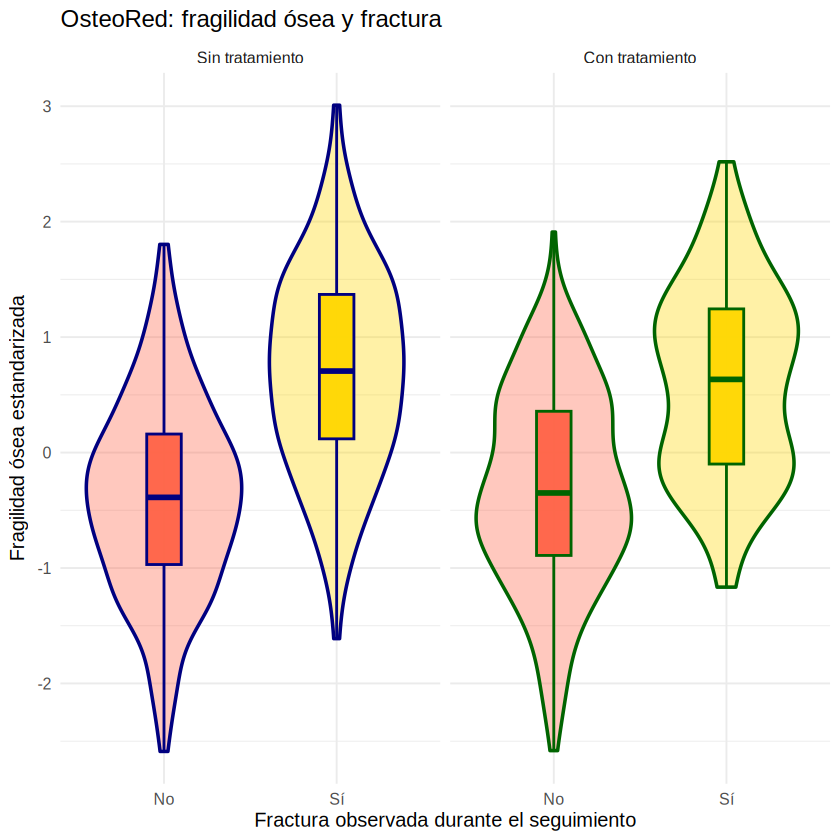

In [87]:
ggplot(
    datos_grafico,
    aes(
        x = fractura,
        y = x1,
        fill = fractura,
        colour = tratamiento
        )
    ) + geom_violin(
        alpha = 0.35,
        linewidth = 1.0
    ) + geom_boxplot(
        width = 0.2,
        alpha = 0.95,
        linewidth = 0.8,
        outlier.alpha = 0.4,
        outlier.size = 1.2
    ) + facet_wrap(
        ~ tratamiento
    ) + scale_fill_manual(
        values = c(
            "No" = "Tomato",
            "Sí" = "Gold"
            )
    ) + scale_colour_manual(
        values = c(
            "Sin tratamiento" = "Navy",
            "Con tratamiento" = "DarkGreen"
            )
    ) + labs(
        title = "OsteoRed: fragilidad ósea y fractura",
        x = "Fractura observada durante el seguimiento",
        y = "Fragilidad ósea estandarizada"
    ) + guides(
        fill = "none",
        colour = "none"
    ) + theme_minimal(
        base_size = 12)


### Observaciones:
- En ambos grupos de tratamiento, las pacientes con fractura presentan una mediana de fragilidad mayor que las pacientes sin fractura.
- Las distribuciones se solapan: la fragilidad aporta información sobre el resultado, pero no separa por completo ambos grupos.
- Poca diferencia visual entre Con/Sin Tratamiento.


El violín responde a la pregunta de cómo se distribuye la fragilidad entre quienes presentaron una fractura y quienes no.

-----

# Para una fragilidad dada, ¿qué probabilidad de fractura estimamos?

Para nuestro análisis, vamos a dividir nuestros datos en tramos. Para ello hemos definido la función "resumen".

In [88]:
delta= 1/4

In [89]:
resumen_global <- resumen(ancho = delta, set = datos_grafico, resumir = "x1")

In [90]:
resumen_tratamiento <- resumen(ancho = delta, set = datos_grafico, resumir = "x1", agrupacion = "tratamiento")

In [102]:
head(resumen_global)
head(resumen_tratamiento)

,tramo,n,fracturas,fragilidad,fragilidad_u,fracturas_u
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,"[-2.75,-2.5]",2,0,-5.170348,-2.585174,0.00000000
2,"(-2.5,-2.25]",7,0,-16.425913,-2.346559,0.00000000
3,"(-2.25,-2]",8,0,-16.570303,-2.071288,0.00000000
4,"(-2,-1.75]",12,0,-23.004767,-1.917064,0.00000000
5,"(-1.75,-1.5]",19,1,-30.702229,-1.615907,0.05263158
6,"(-1.5,-1.25]",37,1,-49.957584,-1.350205,0.02702703


,tramo,tratamiento,n,fracturas,fragilidad,fragilidad_u,fracturas_u
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,"[-2.75,-2.5]",Sin tratamiento,1,0,-2.588764,-2.588764,0.00000000
2,"(-2.5,-2.25]",Sin tratamiento,3,0,-7.169042,-2.389681,0.00000000
3,"(-2.25,-2]",Sin tratamiento,5,0,-10.425807,-2.085161,0.00000000
4,"(-2,-1.75]",Sin tratamiento,6,0,-11.565117,-1.927520,0.00000000
5,"(-1.75,-1.5]",Sin tratamiento,10,1,-16.169814,-1.616981,0.10000000
6,"(-1.5,-1.25]",Sin tratamiento,21,1,-28.428368,-1.353732,0.04761905


# Primer modelo: una recta para la media
Como ever vale 0 o 1, su media condicional coincide con una probabilidad de fractura. Empezamos aproximando esa media mediante una recta en función de la fragilidad:


```
ever ~ x1
```


Este modelo todavía no incluye tratamiento y, por tanto, estima una única recta común. Colorear las observaciones por tratamiento permite distinguir los grupos, pero no añade esa variable al modelo.

Comprobaremos si sus predicciones son compatibles con probabilidades y cómo se comportan sus residuos.

In [91]:
model = lm(ever ~ x1, data = cohorte)

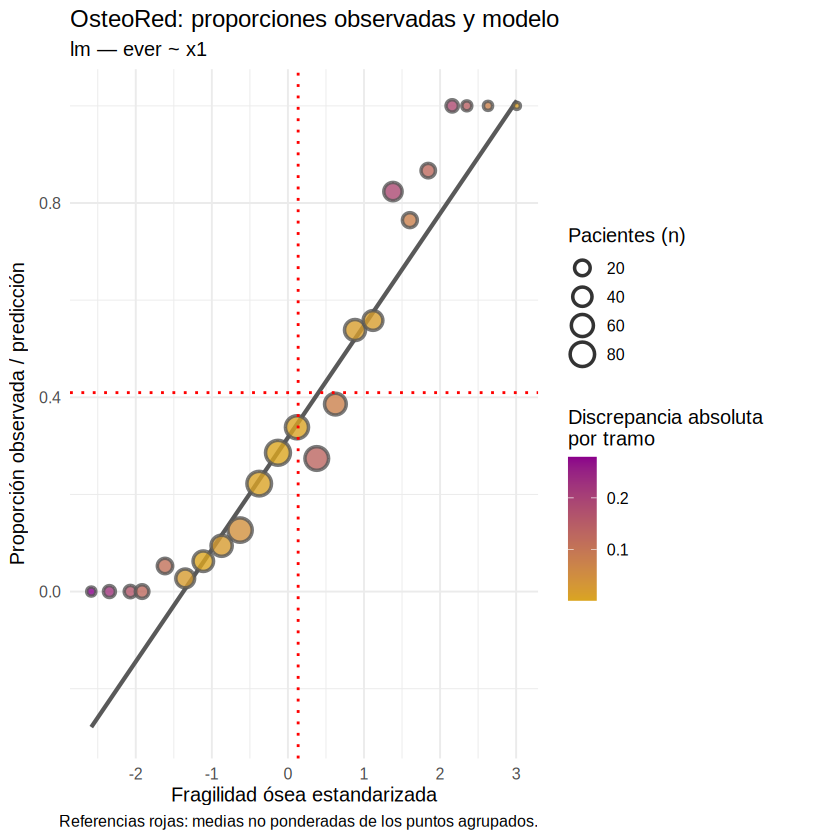

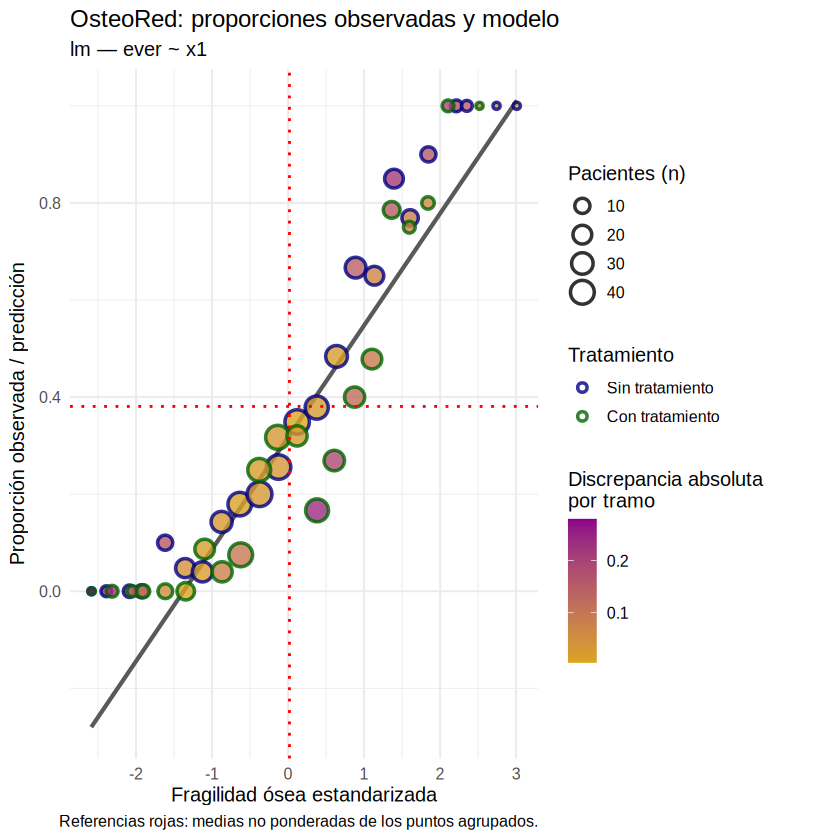

In [92]:
visualizar_ajuste(resumen_global, model)

visualizar_ajuste(resumen_tratamiento, model)

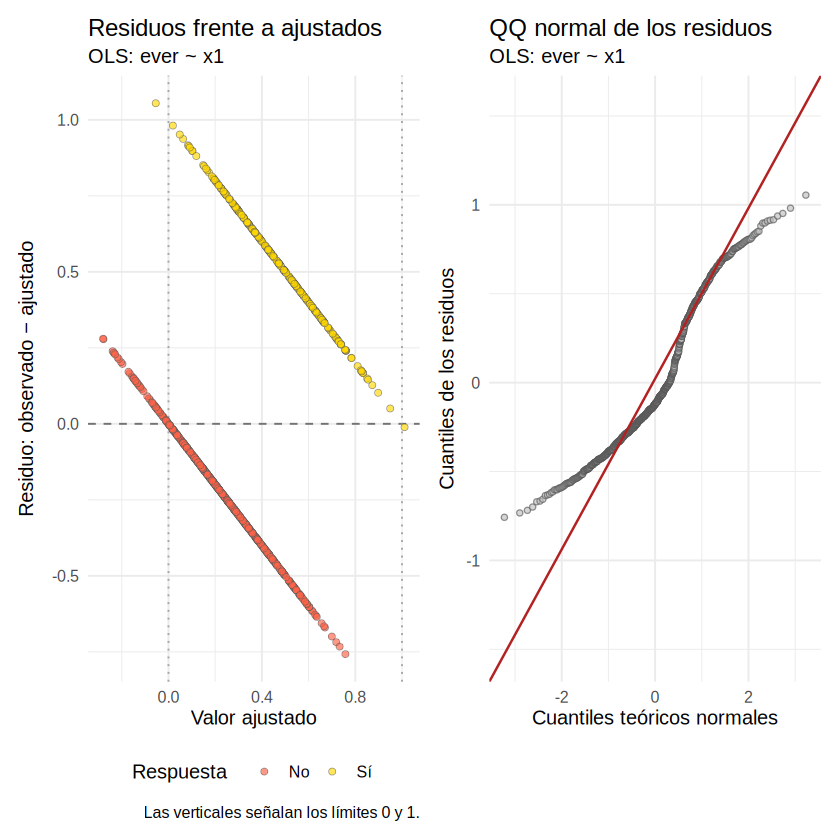

In [93]:
diagnosticar(model)

### Diagnóstico del modelo lineal
En el panel izquierdo, cada punto representa una paciente utilizada en el ajuste. Su posición horizontal es la predicción del modelo y su posición vertical es el residuo: observado menos ajustado.

Las verticales señalan los límites de una probabilidad. Un punto a la izquierda de 0 o a la derecha de 1 corresponde a una predicción incompatible con esa interpretación. Examinamos así las predicciones de las pacientes utilizadas en el ajuste.

Las dos ramas tienen una explicación algebraica. Si no hubo fractura, el residuo es −ajustado; si la hubo, es 1 − ajustado. Las ramas están separadas por una unidad porque los dos resultados posibles son 0 y 1.

El panel derecho compara la distribución de esos mismos residuos con una referencia normal. Una desviación marcada respecto a su recta indicaría que esa distribución empírica no se aproxima bien a una normal.

#  Modelar una probabilidad con un GLM binomial
La respuesta seguirá siendo binaria. Ahora utilizamos una distribución Bernoulli y un enlace logit, que relaciona un predictor lineal con una probabilidad entre 0 y 1.

Incorporamos también el tratamiento mediante la fórmula ever ~ x1 + x2. Esto permite plantear la asociación entre tratamiento y fractura al comparar pacientes de igual fragilidad.

El primer OLS utilizaba solo x1. Para comparar las dos especificaciones manteniendo las mismas covariables, utilizaremos después el OLS fit_ols, que también contiene x1 + x2.

In [94]:
model_candidate = lm(ever ~ x1 + x2, data = cohorte)

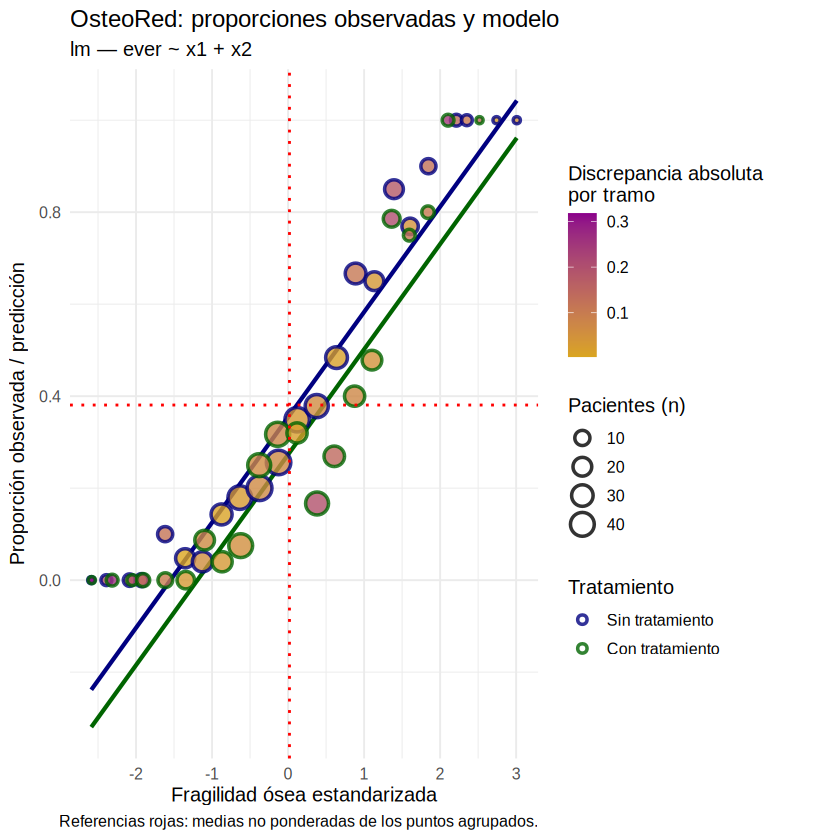

In [95]:
visualizar_ajuste(resumen_tratamiento, model_candidate)

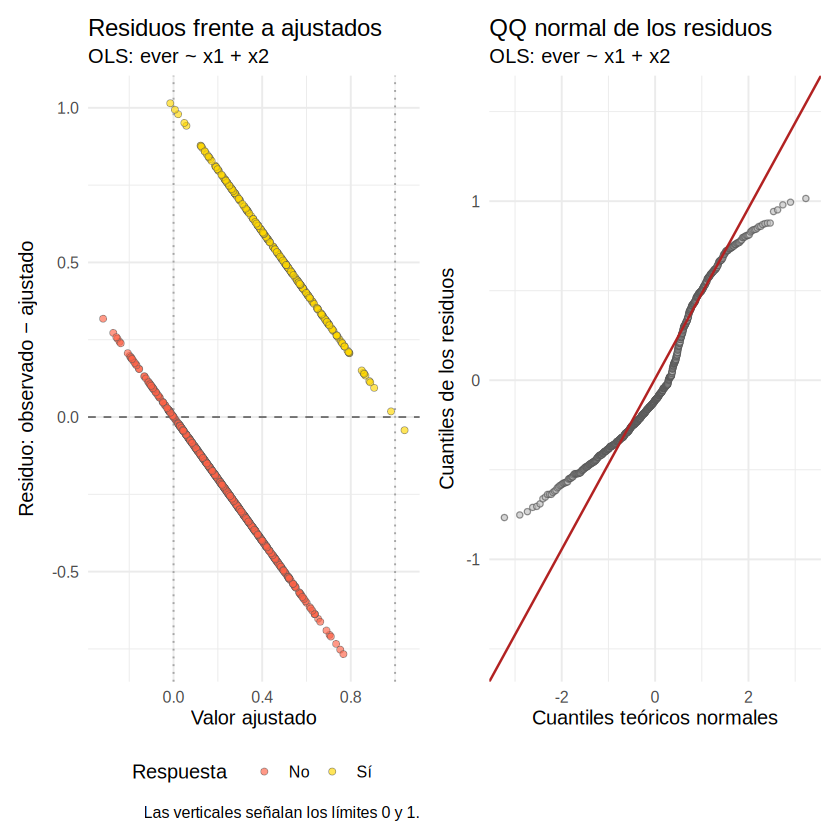

In [96]:
diagnosticar(model_candidate)

In [97]:
modelo_fractura <- glm(
  ever ~ x1 + x2,
  data = cohorte,
  family = binomial(link = "logit")
)

coef(modelo_fractura)
nobs(modelo_fractura)

(Intercept)          x1          x2 
 -0.8116891   1.4013174  -0.4995010

[1] 803

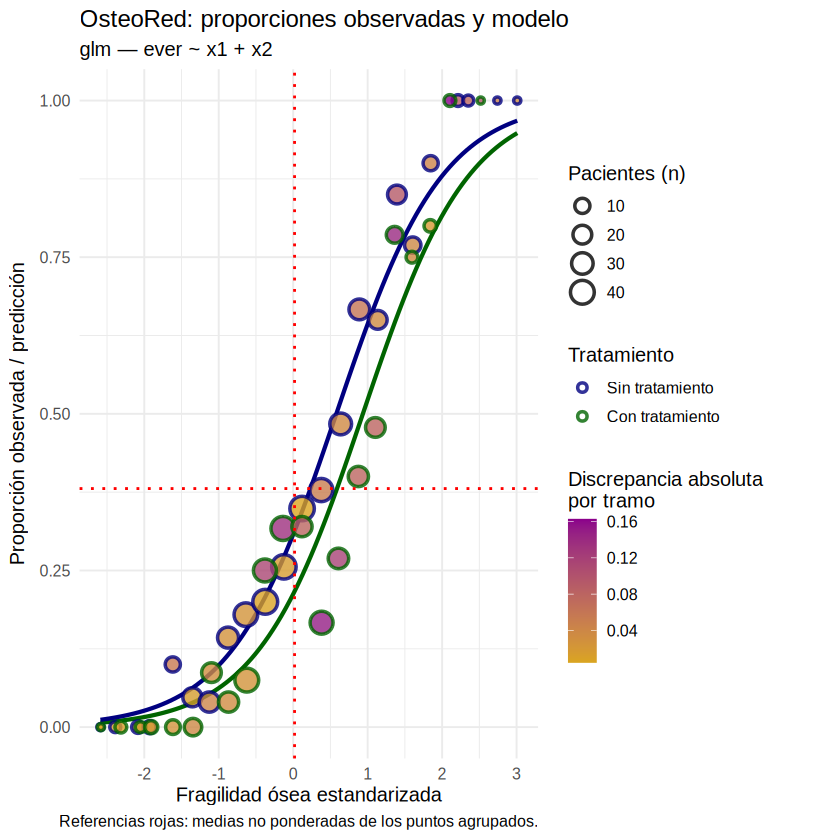

In [98]:
visualizar_ajuste(resumen_tratamiento, modelo_fractura)

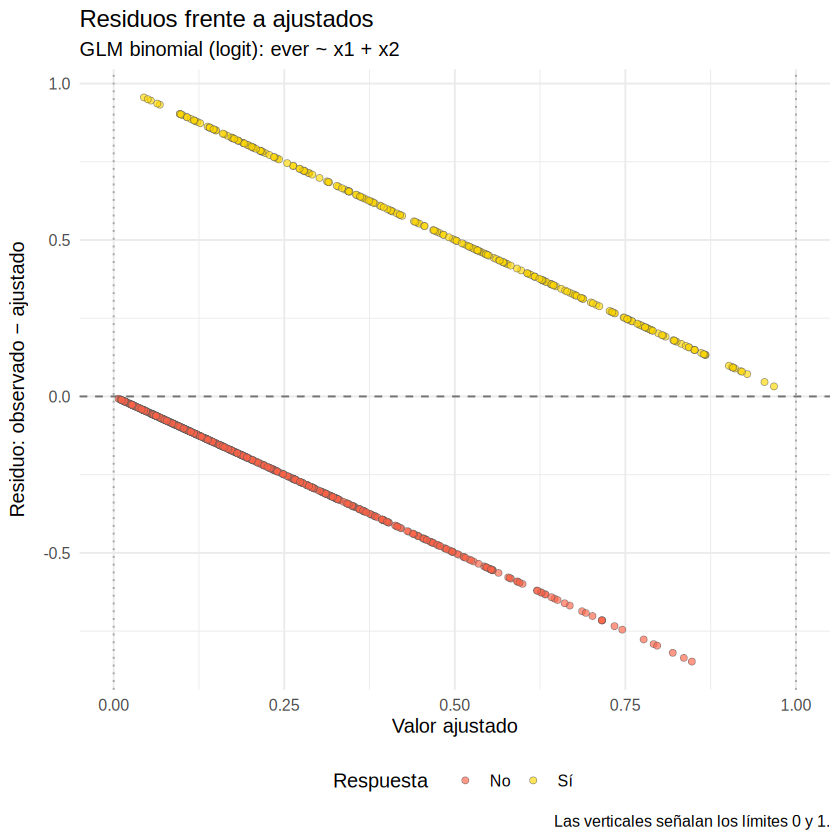

In [99]:
diagnosticar(modelo_fractura)

¿Cómo se relaciona la fragilidad con haber presentado una fractura y qué asociación presenta el tratamiento al comparar mujeres con la misma fragilidad?

In [103]:
# Mismo nivel de fragilidad, distinto tratamiento
perfiles <- data.frame(x1 = c(0, 0), x2 = c(0, 1))

α <- family(modelo_fractura)$linkinv
η <- predict(modelo_fractura, newdata = perfiles, type = "link")

cbind(perfiles, η = η, probabilidad = α(η))

,x1,x2,η,probabilidad
,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0,-0.8116891,0.3075307
2,0,1,-1.3111901,0.2122878
